# Modélisation : ALS sur MovieLens 32M

## Imports

In [7]:
from pathlib import Path

from pyspark.sql import SparkSession
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

In [8]:
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

## Config et builder session Spark

In [9]:
spark = (
    SparkSession.builder
    .master("local[*]")                             # use all cpu cores
    .config("spark.driver.memory", "8g")            # lots of memeory available
    .config("spark.sql.shuffle.partitions", "16")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

## Chargement des données

In [10]:
# dans un notebook, __file__ n'existe pas : le dossier courant est celui du notebook
DATA_DIR = Path("data/clean").resolve()
path_movies_csv = str(DATA_DIR / "movies" / "data_clean_movies.csv")
path_ratings_csv = str(DATA_DIR / "ratings" / "data_clean_ratings.csv")

df_movies = spark.read.csv(path_movies_csv, header=True, inferSchema=True, escape='"')  # quotes inside titles are doubled ("")
df_ratings = spark.read.csv(path_ratings_csv, header=True, schema="userId INT, movieId INT, rating FLOAT, timestamp LONG")

# drop useless column

df_ratings = df_ratings.select("userId", "movieId", "rating").cache()

## Print info

In [11]:
df_movies.show()
df_ratings.show()

df_movies.printSchema()
df_ratings.printSchema()

+-------+--------------------+--------------------+
|movieId|               title|              genres|
+-------+--------------------+--------------------+
|      1|    Toy Story (1995)|Adventure|Animati...|
|      2|      Jumanji (1995)|Adventure|Childre...|
|      3|Grumpier Old Men ...|      Comedy|Romance|
|      4|Waiting to Exhale...|Comedy|Drama|Romance|
|      5|Father of the Bri...|              Comedy|
|      6|         Heat (1995)|Action|Crime|Thri...|
|      7|      Sabrina (1995)|      Comedy|Romance|
|      8| Tom and Huck (1995)|  Adventure|Children|
|      9| Sudden Death (1995)|              Action|
|     10|    GoldenEye (1995)|Action|Adventure|...|
|     11|American Presiden...|Comedy|Drama|Romance|
|     12|Dracula: Dead and...|       Comedy|Horror|
|     13|        Balto (1995)|Adventure|Animati...|
|     14|        Nixon (1995)|               Drama|
|     15|Cutthroat Island ...|Action|Adventure|...|
|     16|       Casino (1995)|         Crime|Drama|
|     17|Sen

## Model configuration

In [12]:
als = ALS(maxIter=10, regParam=0.2, rank=5, userCol="userId", itemCol="movieId", ratingCol="rating", coldStartStrategy="drop", nonnegative=True,
          numUserBlocks=16, numItemBlocks=16)  # from 10 to 16, all threads are used

df_ratings_train, df_ratings_test = df_ratings.randomSplit([0.8,0.2], 42)

als_model = als.fit(df_ratings_train)

preds = als_model.transform(df_ratings_test).cache()  # keep in cache

preds.show(5)

+------+-------+------+----------+
|userId|movieId|rating|prediction|
+------+-------+------+----------+
|    12|   8948|   4.0|  2.363831|
|    12|   2393|   0.5| 2.6570568|
|    12|   2858|   5.0|  2.804924|
|    12|   2248|   2.0|  2.815061|
|    18|   2324|   4.0|  4.007272|
+------+-------+------+----------+
only showing top 5 rows


## Evaluation

In [13]:
eval = RegressionEvaluator(metricName='rmse', labelCol="rating", predictionCol="prediction")

rmse = eval.evaluate(preds)
r2 = eval.evaluate(preds, {eval.metricName: 'r2'})
mae = eval.evaluate(preds, {eval.metricName: 'mae'})
var = eval.evaluate(preds, {eval.metricName: 'var'})

print(f"The model evaluation : \nrmse = {rmse}\nr2 = {r2}\nmae = {mae}\nvar = {var}\n")

The model evaluation : 
rmse = 0.8555379381704018
r2 = 0.34738966863213994
mae = 0.6675827555099186
var = 0.39629778643578356



## Hyperparameters tuning

In [14]:
param_grid = ParamGridBuilder().addGrid(
    als.rank, [5,10,15,20,25]
    ).addGrid(
        als.maxIter, [10]
    ).addGrid(
        als.regParam, [0.01,0.05,0.15,0.2,0.25,0.3]
    ).build()

# split 80/20
tvs = TrainValidationSplit(
    estimator=als,
    estimatorParamMaps=param_grid,
    evaluator=eval,
    trainRatio=0.8,
    seed=42
)

# tuning on 1/5 of the csv to minimize process time
df_tuning = df_ratings_train.sample(fraction=0.2, seed=42).cache()

als_model = tvs.fit(df_tuning)

## Get RMSE scores and parameters to compare

In [15]:
rmse_scores = als_model.validationMetrics
param_maps = als_model.getEstimatorParamMaps()

model_acc = []

#iteration to store the comparison

for param_maps, rmse in zip(param_maps, rmse_scores):
    params = {param.name: value for param, value in param_maps.items()}
    params['rmse'] = rmse
    model_acc.append(params)

## Visualisation

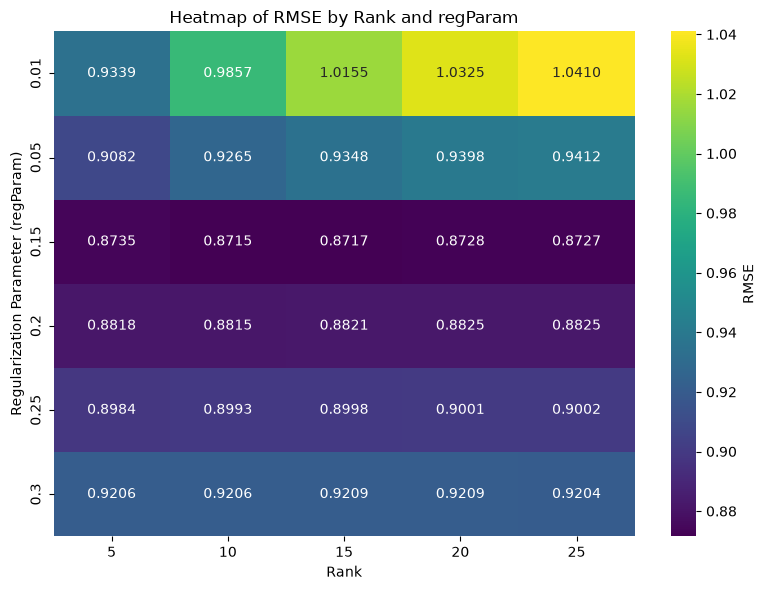

In [17]:
# The .venv (created with uv) doesn't find the Tcl/Tk files of the Python installation,
# so matplotlib can't open its window ("Can't find a usable init.tcl") -> give it their path

"""tcl_dir = os.path.join(sys.base_prefix, "tcl")
if os.path.isdir(tcl_dir):
    os.environ.setdefault("TCL_LIBRARY", os.path.join(tcl_dir, "tcl8.6"))
    os.environ.setdefault("TK_LIBRARY", os.path.join(tcl_dir, "tk8.6"))
"""

#dataframing the model_acc
df_rating_acc = pd.DataFrame(model_acc)

#griding the dataframe

heatmap_data = df_rating_acc.pivot(index='regParam', columns='rank', values='rmse')

#ploting the grid

plt.figure(figsize=(8,6))
sns.heatmap(heatmap_data, annot=True, fmt=".4f", cmap='viridis', cbar_kws={'label': 'RMSE'})
plt.title('Heatmap of RMSE by Rank and regParam')
plt.xlabel('Rank')
plt.ylabel('Regularization Parameter (regParam)')

plt.tight_layout()

# Save the heatmap
heatmap_path = Path("visuals/als_rmse_heatmap.png").resolve()
heatmap_path.parent.mkdir(exist_ok=True)
plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
plt.show()